# Mini Proyecto – Equipo 2: Detección de Fraude en una Pasarela de Pagos
## Capa 1 (Núcleo PyTorch) – Parte A: datos, preprocesamiento y evaluación

**Curso:** Redes Neuronales y Aprendizaje Profundo – UNITEC – Sección 1905 – Ing. Kevin Fúnez
**Equipo 2:** Brandon Hernández, Jesús Rodríguez, Walter Doblado, Diego Lara, Carlos Flores

Este notebook recorre la primera capa del sistema inteligente. El código vive en el paquete `nucleo/` del repositorio (programación orientada a objetos) y aquí se importa y se ejecuta paso a paso para mostrar los resultados de cada fase:

1. Ingesta del dataset y análisis del desbalance de clases.
2. Partición estratificada y estandarización Z-score (escalador guardado).
3. `Dataset` personalizado y `DataLoader` por mini-batches.
4. Evaluación del modelo entrenado sobre el conjunto de prueba.
5. Elección del umbral de decisión.
6. Dinámica de optimización: SGD frente a AdamW.

### Fase 0. Preparación del entorno

In [1]:
# Librerías del sistema para ubicar el repositorio
import os, sys
from pathlib import Path

# Detecta si el notebook corre en Google Colab
EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    # En Colab se clona el repositorio del equipo (solo la primera vez)
    if not Path("miniproyecto-equipo2").exists():
        !git clone -q https://github.com/KDBlitzz/miniproyecto-equipo2.git
    %cd miniproyecto-equipo2
else:
    # En local (VS Code) se sube de carpeta hasta encontrar la raíz del repositorio
    raiz = Path.cwd()
    while not (raiz / "nucleo").exists() and raiz != raiz.parent:
        raiz = raiz.parent
    os.chdir(raiz)

# Permite importar el paquete nucleo/ desde la raíz
sys.path.insert(0, os.getcwd())
print("Raíz del proyecto:", os.getcwd())

Raíz del proyecto: d:\UNITEC y Personal\Unitec\Tareas\17vo Periodo\Sistemas Inteligentes\MiniProyectoEquipo2\miniproyecto-equipo2


In [2]:
# Librerías numéricas y de PyTorch
import json
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display

# Módulos propios de la Capa 1 (paquete nucleo/)
from nucleo.datos import (COLUMNAS_ENTRADA, RUTA_ARTEFACTOS, Escalador, TransaccionesDataset,
                          crear_dataloaders, descargar_dataset, graficar_desbalance,
                          particionar, resumen_desbalance, resumen_particion)
from nucleo.evaluacion import (barrido_umbral, calcular_metricas, elegir_umbral,
                               graficar_barrido_umbral, graficar_curva_pr,
                               graficar_matriz_confusion, predecir_probabilidades)
from nucleo.modelo import DetectorFraudeMLP

# Semilla fija para que los resultados sean reproducibles
torch.manual_seed(42)
np.random.seed(42)
FIGURAS = RUTA_ARTEFACTOS / "figuras"
print("PyTorch", torch.__version__)

PyTorch 2.15.0+cpu


### Fase 1. Ingesta del dataset

Se usa *Credit Card Fraud Detection* (ULB): transacciones reales de tarjetas europeas. Las columnas `V1` a `V28` son componentes PCA anonimizadas y `Amount` es el monto. La etiqueta `Class` vale 1 cuando la transacción es fraude. La versión de OpenML no incluye la columna `Time`, por lo que el modelo trabaja con **29 características**.

In [3]:
# Descarga el dataset desde OpenML la primera vez; después solo lee el CSV local
df = descargar_dataset()
# Dimensiones: filas (transacciones) y columnas (29 entradas + etiqueta)
print("Forma del dataset:", df.shape)
# Características que entran a la red
print("Entradas del modelo:", len(COLUMNAS_ENTRADA))
# Primeras filas para inspeccionar los datos
df.head()

Forma del dataset: (284807, 30)
Entradas del modelo: 29


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


### Fase 2. Análisis del desbalance de clases

In [4]:
# Conteo por clase, porcentaje de fraude y razón negativos/positivos
resumen = resumen_desbalance(df)
print(f"Total de transacciones : {resumen['total']:,}")
print(f"Legítimas              : {resumen['legitimas']:,}")
print(f"Fraudes                : {resumen['fraudes']:,} ({resumen['porcentaje_fraude']:.3f} %)")
print(f"Razón negativos/positivos (pos_weight): {resumen['razon_neg_pos']:.1f}")
# Estadísticas del monto separadas por clase
resumen["monto_por_clase"].round(2)

Total de transacciones : 284,807
Legítimas              : 284,315
Fraudes                : 492 (0.173 %)
Razón negativos/positivos (pos_weight): 577.9


,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.29,250.11,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.21,256.68,0.0,1.00,9.25,105.89,2125.87


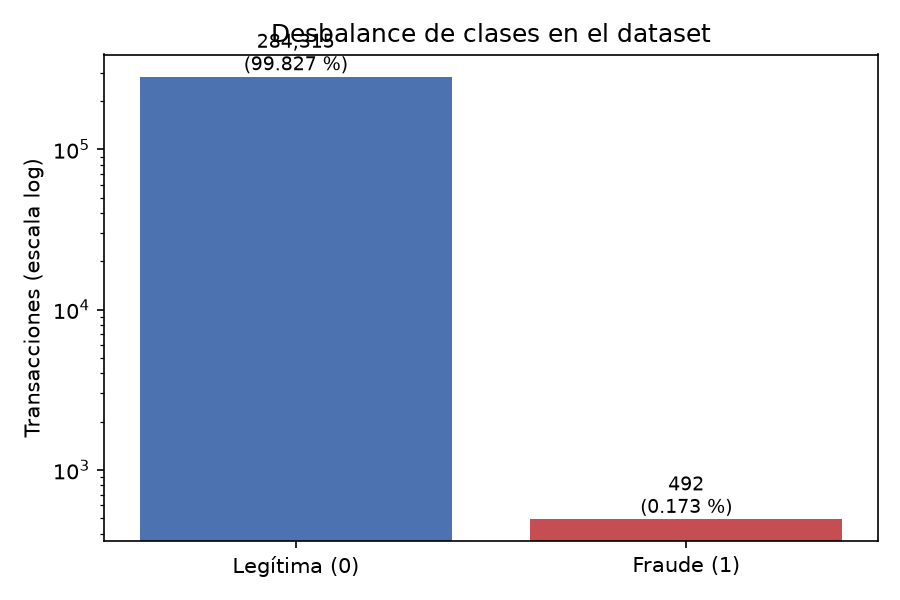

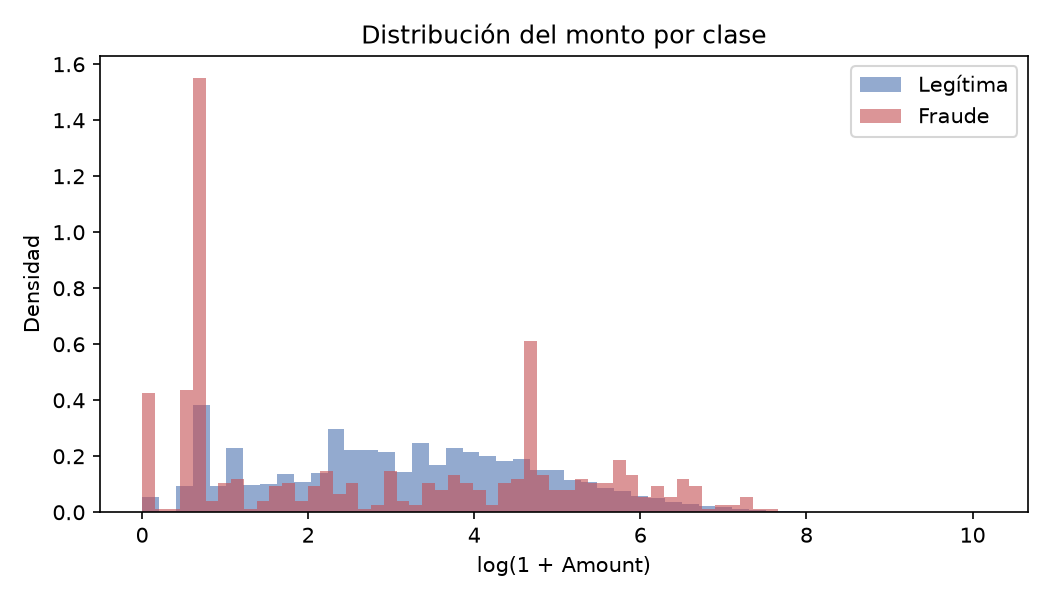

In [5]:
# Genera y guarda las figuras del análisis exploratorio
rutas = graficar_desbalance(df)
# Muestra cada figura guardada dentro del notebook
for ruta in rutas:
    display(Image(filename=str(ruta), width=520))

**Dinámica Práctica: Tu Autoguía de Aprendizaje**
Solo 492 de 284 807 transacciones son fraude (0.173 %). Un modelo que respondiera "legítima" a todo acertaría el 99.83 % de las veces sin detectar un solo fraude; por eso la exactitud (*accuracy*) no sirve como métrica en este problema. Observe además la mediana del monto: 9.25 en los fraudes frente a 22.00 en las legítimas.

### Fase 3. Partición estratificada (70 / 15 / 15)

Con tan pocos fraudes, un corte aleatorio simple podría dejar un subconjunto casi sin positivos. La partición estratificada conserva la misma proporción de fraude en entrenamiento, validación y prueba.

In [6]:
# Dos cortes estratificados: 70 % entrenamiento y el 30 % restante a la mitad
X_train, y_train, X_val, y_val, X_test, y_test = particionar(df, semilla=42)
# Tabla con tamaño, fraudes y porcentaje por subconjunto
resumen_particion(y_train, y_val, y_test)

,transacciones,fraudes,porcentaje_fraude
conjunto,,,
train,199364,344,0.173
val,42721,74,0.173
test,42722,74,0.173


### Fase 4. Estandarización Z-score

$z = \dfrac{x - \mu}{\sigma}$, donde $\mu$ y $\sigma$ se calculan **solo con el conjunto de entrenamiento**. El escalador se guarda en `artefactos/escalador.pkl` para que la API aplique exactamente la misma transformación a cada transacción nueva.

In [7]:
# Ajusta media y desviación únicamente con entrenamiento
escalador = Escalador().ajustar(X_train)
# Transforma los tres subconjuntos con los mismos parámetros
Z_train = escalador.transformar(X_train)
Z_val = escalador.transformar(X_val)
Z_test = escalador.transformar(X_test)
# Guarda el escalador empírico para la Capa 2
ruta_escalador = escalador.guardar()
print("Escalador guardado en:", ruta_escalador.name)
# Comprobación: entrenamiento queda con media 0 y desviación 1
print(f"Train -> media {Z_train.mean():+.4f} | desviación {Z_train.std(axis=0).mean():.4f}")
# Validación queda cerca pero no exacta, porque el escalador no la vio
print(f"Val   -> media {Z_val.mean():+.4f} | desviación {Z_val.std(axis=0).mean():.4f}")
# El archivo recargado reproduce la misma transformación
print("El .pkl reproduce la transformación:", np.allclose(Escalador.cargar(ruta_escalador).transformar(X_val), Z_val))

Escalador guardado en: escalador.pkl
Train -> media -0.0000 | desviación 1.0000
Val   -> media +0.0005 | desviación 1.0003
El .pkl reproduce la transformación: True


**Dinámica Práctica: Tu Autoguía de Aprendizaje**
Pruebe ajustar el escalador con todo el dataset en lugar de solo entrenamiento. Los números casi no cambian, pero el procedimiento sería incorrecto: información de validación y prueba se filtraría al entrenamiento (*data leakage*) y las métricas dejarían de medir datos realmente nuevos.

### Fase 5. Dataset personalizado y DataLoader

`TransaccionesDataset` hereda de `torch.utils.data.Dataset` e implementa `__len__` y `__getitem__`. El `DataLoader` entrega los datos en mini-batches y baraja únicamente el conjunto de entrenamiento.

In [8]:
# Pipeline completo: partición, escalado, Datasets y DataLoaders (lote de 512)
datos = crear_dataloaders(tamano_lote=512, semilla=42, df=df)
loader_train, loader_val, loader_test = datos["loader_train"], datos["loader_val"], datos["loader_test"]
# Tamaño de cada Dataset (método __len__)
print("Transacciones -> train", len(datos["dataset_train"]), "| val", len(datos["dataset_val"]), "| test", len(datos["dataset_test"]))
# Un elemento individual (método __getitem__): 29 características y su etiqueta
x0, y0 = datos["dataset_train"][0]
print("Elemento 0 -> x", tuple(x0.shape), x0.dtype, "| y", tuple(y0.shape), y0.dtype)
# Un mini-batch completo
lote_X, lote_y = next(iter(loader_train))
print("Primer lote  -> X", tuple(lote_X.shape), "| y", tuple(lote_y.shape))
print("Lotes por época:", len(loader_train))

Transacciones -> train 199364 | val 42721 | test 42722
Elemento 0 -> x (29,) torch.float32 | y (1,) torch.float32
Primer lote  -> X (512, 29) | y (512, 1)
Lotes por época: 390


In [9]:
# Recorre una época y cuenta los fraudes que trae cada lote
fraudes_por_lote = [int(y.sum().item()) for _, y in loader_train]
# Lotes en los que la red no ve ningún fraude
sin_fraude = sum(1 for f in fraudes_por_lote if f == 0)
print(f"Lotes sin ningún fraude: {sin_fraude} de {len(fraudes_por_lote)} ({100 * sin_fraude / len(fraudes_por_lote):.0f} %)")
print(f"Fraudes promedio por lote: {np.mean(fraudes_por_lote):.2f} | máximo en un lote: {max(fraudes_por_lote)}")

Lotes sin ningún fraude: 149 de 390 (38 %)
Fraudes promedio por lote: 0.88 | máximo en un lote: 4


**Dinámica Práctica: Tu Autoguía de Aprendizaje**
Con lotes de 512 hay menos de un fraude por lote en promedio, y en más de un tercio de los pasos de gradiente la red solo ve transacciones legítimas. Ese es el motivo por el que el enunciado pide modificar la función de costo: hay que darle más peso a los pocos ejemplos de fraude. Cambie el tamaño de lote a 2048 y observe cómo baja la proporción de lotes vacíos.

### Fase 6. Modelo entrenado

La arquitectura, las funciones de costo (BCE estándar, BCE ponderada y Focal Loss) y el bucle de entrenamiento explícito se desarrollan en la Parte B (`nucleo/modelo.py`, `nucleo/perdidas.py`, `nucleo/entrenamiento.py`). Aquí se carga el modelo exportado, que es el mismo que sirve la API.

In [10]:
# Configuración exportada junto con el modelo (arquitectura, umbral, pérdida)
config = json.loads((RUTA_ARTEFACTOS / "config_inferencia.json").read_text(encoding="utf-8"))
umbral = float(config["umbral"])
# Reconstruye la arquitectura 29 -> 64 -> 32 -> 1
modelo = DetectorFraudeMLP(config["dim_entrada"], tuple(config["dims_ocultas"]), config["p_dropout"])
# Carga los pesos entrenados
modelo.load_state_dict(torch.load(RUTA_ARTEFACTOS / "modelo_fraude.pth", map_location="cpu", weights_only=True))
print(modelo)
print("Parámetros entrenables:", modelo.contar_parametros())
print("Pérdida de entrenamiento:", config.get("perdida"), "| umbral de decisión:", umbral)

DetectorFraudeMLP(
  (capa1): Linear(in_features=29, out_features=64, bias=True)
  (bn1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (capa2): Linear(in_features=64, out_features=32, bias=True)
  (bn2): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (salida): Linear(in_features=32, out_features=1, bias=True)
  (activacion): ReLU()
  (dropout): Dropout(p=0.3, inplace=False)
)
Parámetros entrenables: 4225
Pérdida de entrenamiento: focal | umbral de decisión: 0.6


### Fase 7. Módulo de validación y métricas

`predecir_probabilidades` pone el modelo en modo evaluación (`modelo.eval()`) y recorre el `DataLoader` dentro de `with torch.no_grad():`, de modo que no se construye el grafo computacional. Las métricas se calculan para la clase fraude:

- **Recall:** de los fraudes reales, cuántos se bloquearon.
- **Precision:** de lo bloqueado, cuánto era realmente fraude.
- **F1:** media armónica de las dos anteriores.
- **PR-AUC:** área bajo la curva precision-recall, la métrica de resumen adecuada para datos desbalanceados.

In [11]:
# Probabilidades del modelo en validación (donde se eligió el umbral)
prob_val, etiquetas_val = predecir_probabilidades(modelo, loader_val)
# Probabilidades en prueba (datos que el modelo nunca vio)
prob_test, etiquetas_test = predecir_probabilidades(modelo, loader_test)
# Métricas con el umbral exportado
m_val = calcular_metricas(etiquetas_val, prob_val, umbral)
m_test = calcular_metricas(etiquetas_test, prob_test, umbral)
# Tabla comparativa validación vs prueba
claves = ["accuracy", "precision_fraude", "recall_fraude", "f1_fraude", "pr_auc", "roc_auc", "tn", "fp", "fn", "tp"]
pd.DataFrame({"validación": [m_val[k] for k in claves], "prueba": [m_test[k] for k in claves]}, index=claves).round(4)

,validación,prueba
accuracy,0.9992,0.9994
precision_fraude,0.7632,0.8788
recall_fraude,0.7838,0.7838
f1_fraude,0.7733,0.8286
pr_auc,0.7695,0.8286
roc_auc,0.9495,0.9782
tn,42629.0000,42640.0000
fp,18.0000,8.0000
fn,16.0000,16.0000
tp,58.0000,58.0000


In [12]:
# Línea base trivial: un modelo que aprueba todas las transacciones
accuracy_trivial = 1.0 - float(etiquetas_test.mean())
print(f"Accuracy del modelo que aprueba todo: {accuracy_trivial:.4f} (detecta 0 fraudes)")
print(f"Accuracy de nuestro modelo          : {m_test['accuracy']:.4f}")
print(f"Fraudes en prueba: {int(etiquetas_test.sum())} | detectados: {m_test['tp']} | escapados: {m_test['fn']}")
print(f"Legítimas bloqueadas por error: {m_test['fp']} de {m_test['tn'] + m_test['fp']:,}")

Accuracy del modelo que aprueba todo: 0.9983 (detecta 0 fraudes)
Accuracy de nuestro modelo          : 0.9994
Fraudes en prueba: 74 | detectados: 58 | escapados: 16
Legítimas bloqueadas por error: 8 de 42,648


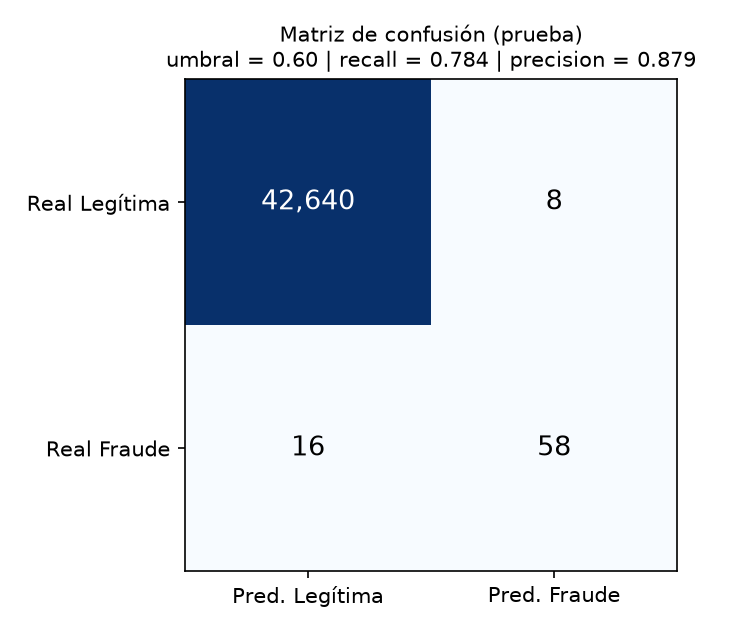

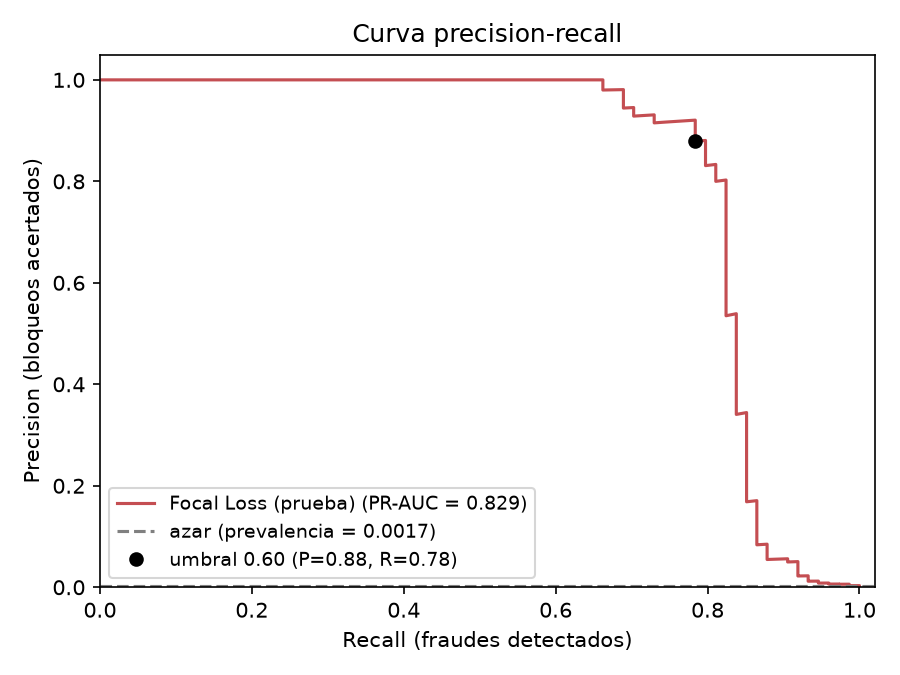

In [13]:
# Matriz de confusión sobre el conjunto de prueba
display(Image(filename=str(graficar_matriz_confusion(etiquetas_test, prob_test, umbral, FIGURAS / "03_matriz_confusion_test.png", "Matriz de confusión (prueba)")), width=460))
# Curva precision-recall con el punto del umbral elegido
display(Image(filename=str(graficar_curva_pr(etiquetas_test, prob_test, FIGURAS / "04_curva_pr_test.png", umbral, "Focal Loss (prueba)")), width=520))

**Dinámica Práctica: Tu Autoguía de Aprendizaje**
Compare la exactitud del modelo con la del modelo trivial: la diferencia es de apenas una décima de punto porcentual, aunque uno detecta la mayoría de los fraudes y el otro ninguno. La matriz de confusión y la curva precision-recall son las que muestran el rendimiento real.

### Fase 8. Elección del umbral de decisión

La red entrega una probabilidad; la pasarela necesita una decisión (`approved` o `blocked`). El umbral que convierte una en otra se elige sobre **validación**, nunca sobre prueba. Subirlo reduce las falsas alarmas pero deja escapar más fraudes; bajarlo hace lo contrario.

In [14]:
# Efecto del umbral sobre precision, recall, F1 y los errores (validación)
barrido_umbral(etiquetas_val, prob_val, [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]).round(3)

,precision_fraude,recall_fraude,f1_fraude,fp,fn,tp
umbral,,,,,,
0.1,0.146,0.838,0.248,363,12,62
0.2,0.319,0.824,0.460,130,13,61
0.3,0.531,0.811,0.642,53,14,60
0.4,0.612,0.811,0.698,38,14,60
0.5,0.663,0.797,0.724,30,15,59
0.6,0.763,0.784,0.773,18,16,58
0.7,0.952,0.541,0.690,2,34,40
0.8,1.000,0.378,0.549,0,46,28
0.9,1.000,0.203,0.337,0,59,15


Criterio F1    -> umbral 0.60 | precision 0.763 | recall 0.784 | FP 18 | FN 16
Criterio costo -> umbral 0.58 | precision 0.738 | recall 0.797 | FP 21 | FN 15
Umbral exportado a la API: 0.60


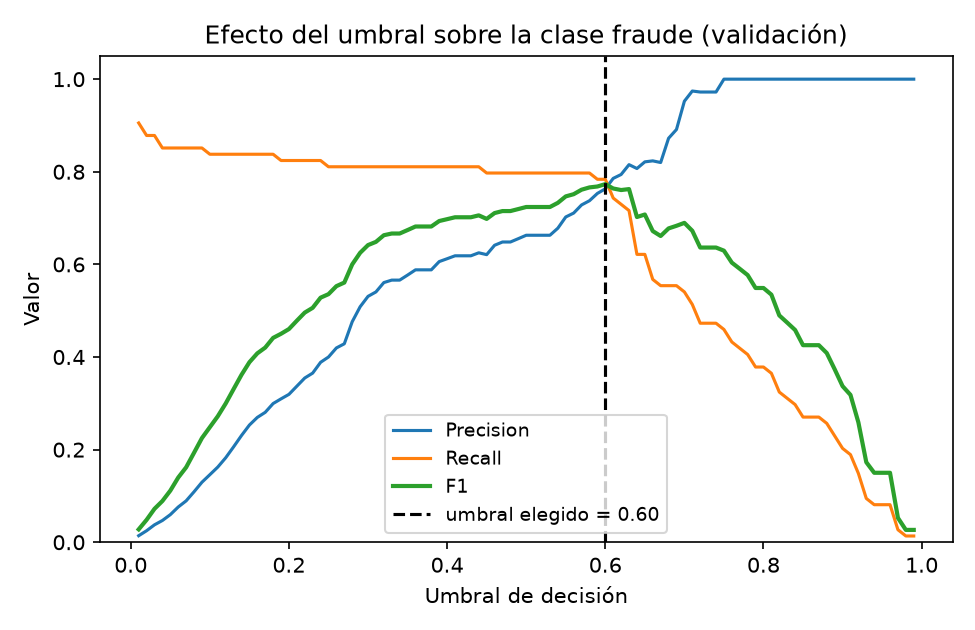

In [15]:
# Umbral que maximiza F1 en validación
u_f1, m_f1 = elegir_umbral(etiquetas_val, prob_val, criterio="f1")
# Umbral que minimiza un costo de negocio: dejar pasar un fraude cuesta 10 veces más que una falsa alarma
u_costo, m_costo = elegir_umbral(etiquetas_val, prob_val, criterio="costo", costo_fn=10.0, costo_fp=1.0)
print(f"Criterio F1    -> umbral {u_f1:.2f} | precision {m_f1['precision_fraude']:.3f} | recall {m_f1['recall_fraude']:.3f} | FP {m_f1['fp']} | FN {m_f1['fn']}")
print(f"Criterio costo -> umbral {u_costo:.2f} | precision {m_costo['precision_fraude']:.3f} | recall {m_costo['recall_fraude']:.3f} | FP {m_costo['fp']} | FN {m_costo['fn']}")
print(f"Umbral exportado a la API: {umbral:.2f}")
# Curvas de precision, recall y F1 en función del umbral
display(Image(filename=str(graficar_barrido_umbral(etiquetas_val, prob_val, FIGURAS / "05_barrido_umbral_validacion.png", umbral)), width=560))

**Dinámica Práctica: Tu Autoguía de Aprendizaje**
Cambie `costo_fn` a 50 (un fraude no detectado cuesta cincuenta veces más que una falsa alarma) y observe hacia dónde se mueve el umbral. La elección del umbral es una decisión de negocio, no solo matemática.

### Fase 9. Dinámica de optimización: SGD frente a AdamW

Se entrenó la misma red (Focal Loss, 29 → 64 → 32 → 1, semilla 42, lote 512, *weight decay* 1e-4) cambiando únicamente el optimizador: AdamW con tasa de aprendizaje 0.001 y SGD con momentum 0.9 y tasa 0.01. Los historiales los escribe el bucle de entrenamiento:

`python -m nucleo.entrenamiento --perdida focal --optimizador sgd --epocas 80 --paciencia 8`

optimizador            AdamW (lr 0.001)  SGD + momentum (lr 0.01)
epocas_corridas               58.000000                 80.000000
mejor_epoca                   50.000000                 78.000000
pr_auc_val                     0.769500                  0.648900
f1_val                         0.773300                  0.774600
precision_val                  0.763200                  0.808800
recall_val                     0.783800                  0.743200
loss_train_final               0.000234                  0.000589
loss_val_final                 0.001574                  0.000787
loss_val_minima                0.000749                  0.000747
epoca_loss_val_minima          4.000000                 78.000000
epoca_pr_auc_0.64              3.000000                 32.000000

Figura: D:\UNITEC y Personal\Unitec\Tareas\17vo Periodo\Sistemas Inteligentes\MiniProyectoEquipo2\miniproyecto-equipo2\artefactos\figuras\06_sgd_vs_adamw.png


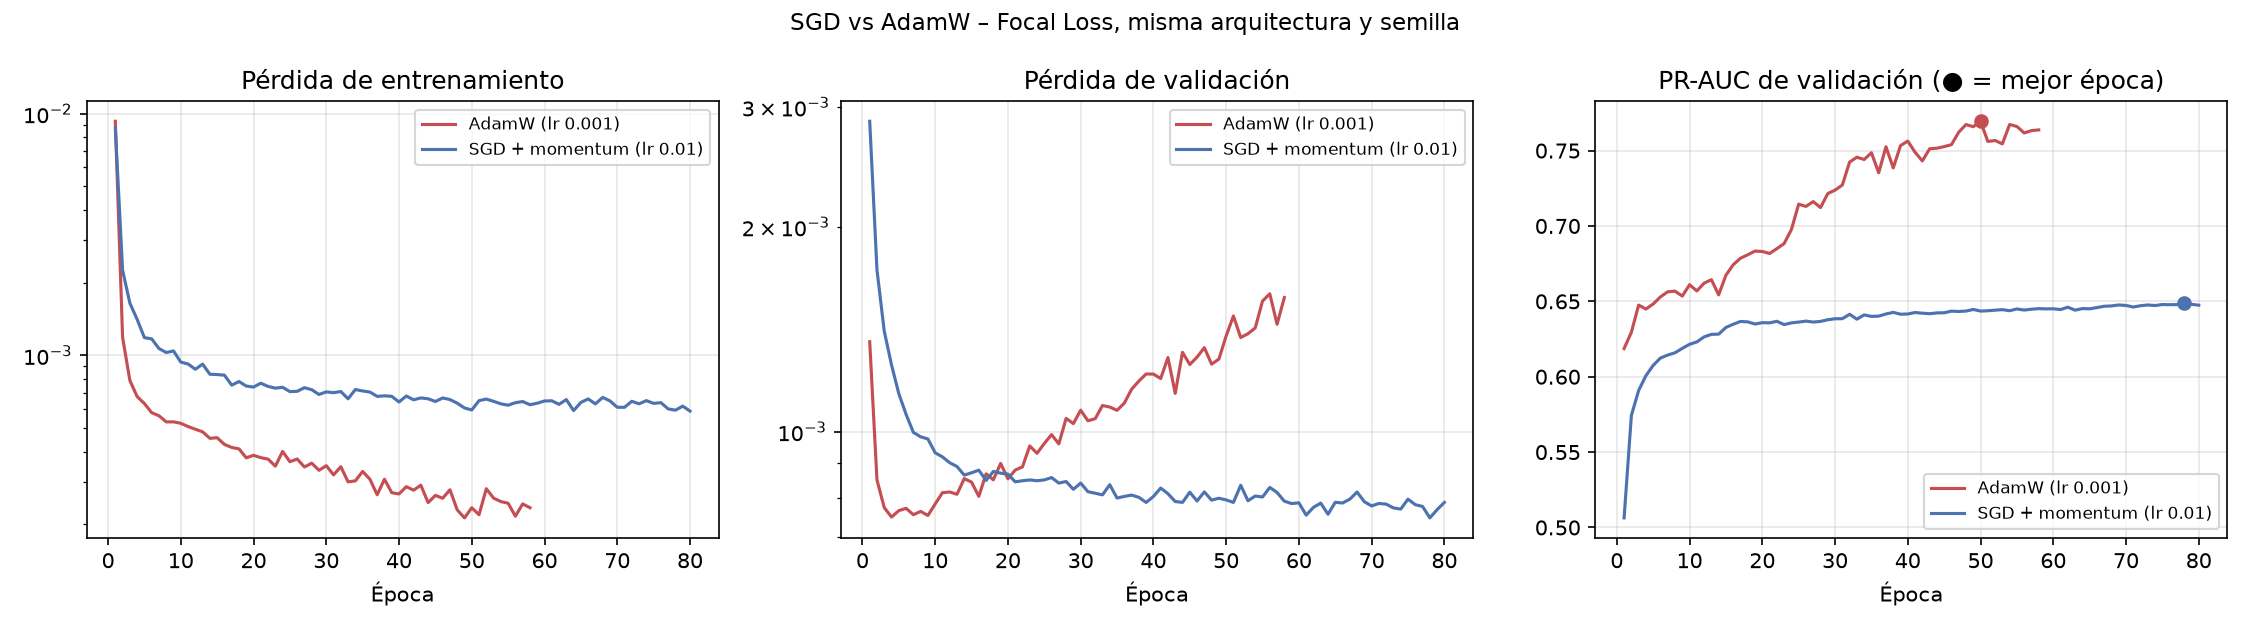

In [16]:
# Lee los historiales de ambas corridas, arma la tabla y guarda la figura comparativa
from nucleo.comparar_optimizadores import principal as comparar_optimizadores
comparar_optimizadores()
# Pérdida de entrenamiento, pérdida de validación y PR-AUC por época
display(Image(filename=str(FIGURAS / "06_sgd_vs_adamw.png"), width=980))

**Dinámica Práctica: Tu Autoguía de Aprendizaje**
Observe tres cosas en la figura. Primero, AdamW alcanza en 3 épocas el PR-AUC que a SGD le toma más de 30. Segundo, las curvas de SGD bajan juntas y terminan cercanas, mientras que con AdamW la pérdida de validación sube después de la época 4 aunque el PR-AUC sigue mejorando: la pérdida mide qué tan calibradas están las probabilidades y el PR-AUC mide qué tan bien se ordenan los fraudes por encima de las legítimas. Tercero, SGD llegó al tope de 80 épocas sin detenerse, por lo que su resultado todavía podía mejorar.

### Fase 10. Comparación de pérdidas y memoria del modelo

La arquitectura evaluada es `29 → Linear(64) → BatchNorm → ReLU → Dropout → Linear(32) → BatchNorm → ReLU → Dropout → Linear(1)`. Se compararon BCE estándar y Focal Loss (`alpha=0.75`, `gamma=2`) con las mismas reglas de entrenamiento y las semillas 42, 1 y 2. La semilla se incluye en el nombre de cada resultado para evitar sobrescrituras.

La BCE estándar no debe describirse como un modelo que no detecta fraudes: con umbral 0.5 puede producir recall nulo en una corrida, pero al ajustar el umbral sobre validación recupera el rendimiento. La comparación agregada se interpreta con cautela porque solo usa tres semillas.


In [ ]:
# Resumen reproducible de las corridas BCE/Focal por semilla
tabla_semillas = pd.read_csv(RUTA_ARTEFACTOS / "tabla_semillas.csv")
tabla_semillas.round(4)

In [ ]:
# Memoria de activaciones que PyTorch guarda para la retropropagación
lote = 512
x = torch.randn(lote, config["dim_entrada"])
modelo.train()
pesos = {p.untyped_storage().data_ptr() for p in modelo.parameters()}
entrada = x.untyped_storage().data_ptr()
guardados = {}

def guardar_tensor(tensor):
    almacen = tensor.untyped_storage()
    guardados[almacen.data_ptr()] = almacen.nbytes()
    return tensor

with torch.autograd.graph.saved_tensors_hooks(guardar_tensor, lambda tensor: tensor):
    modelo(x)
activaciones = {p: n for p, n in guardados.items() if p not in pesos}
sin_entrada = {p: n for p, n in activaciones.items() if p != entrada}
print(f"Activaciones guardadas incluyendo entrada: {sum(activaciones.values()):,} B")
print(f"Activaciones guardadas sin entrada: {sum(sin_entrada.values()):,} B")
print(f"Fórmula simplificada del PDF: {lote * (64 + 64 + 32 + 32 + 1) * 4:,} B")

En esta arquitectura, la medición completa de PyTorch cuenta los tensores necesarios para la retropropagación, incluyendo entrada, salidas intermedias, BatchNorm, ReLU y Dropout. Por eso es mayor que la fórmula simplificada del PDF; ambas cifras responden a definiciones distintas de memoria.

### Cierre de la Parte A

| Fase | Resultado |
|---|---|
| Ingesta | 284 807 transacciones, 492 fraudes (0.173 %), 29 características |
| Partición | 70 / 15 / 15 estratificada, misma proporción de fraude en los tres conjuntos |
| Estandarización | Z-score ajustado con entrenamiento y guardado en `escalador.pkl` |
| DataLoader | 390 lotes de 512 por época; cerca de un tercio no contiene ningún fraude |
| Evaluación en prueba | ver la tabla de la Fase 7 |
| Optimizador | AdamW converge más rápido y con mejor PR-AUC; SGD es más lento pero con curvas más estables |

Los artefactos que esta parte entrega a la Capa 2 son `escalador.pkl`, `muestra_test.csv` y el umbral validado en `config_inferencia.json`.